Importaciones

In [3]:
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import Ridge
from statsmodels.tsa.arima.model import ARIMA
import numpy as np

In [4]:
df = pd.read_csv('../output/df_final.csv')

Selección de datos

In [5]:
datos = df.groupby('fecha').agg({'cantidad': 'sum', 'media': 'mean', 'precipitacion': 'mean'})
datos['fecha'] = pd.to_datetime(datos.index)
datos.set_index('fecha', inplace=True)
datos.sort_index(inplace=True)
datos

,cantidad,media,precipitacion
fecha,,,
2021-01-02,54039.5677,26.9,0.0
2021-01-03,52387.8631,28.3,0.0
2021-01-04,60503.8856,27.0,8.6
2021-01-05,52937.7395,25.5,0.0
2021-01-06,42781.1186,26.4,7.4
...,...,...,...
2021-09-26,50281.8482,23.1,0.0
2021-09-27,44041.0166,27.2,0.0
2021-09-28,36640.0411,23.8,0.8


### Ingeniería de Características
Creamos variables adicionales que pueden tener un gran impacto en las ventas, como el día de la semana, el mes, si es fin de semana, y variables de rezago (*lags*) para capturar la inercia de ventas de días anteriores.

In [6]:
# Copiar los datos para no alterar el dataframe original
datos_eng = datos.copy()

# Variables de calendario
datos_eng['dia_semana'] = datos_eng.index.dayofweek
datos_eng['mes'] = datos_eng.index.month
datos_eng['es_fin_de_semana'] = datos_eng['dia_semana'].isin([5, 6]).astype(int)

# Variables de rezago (lags) de la variable objetivo 'cantidad'
datos_eng['cantidad_lag_1'] = datos_eng['cantidad'].shift(1)
datos_eng['cantidad_lag_7'] = datos_eng['cantidad'].shift(7)

# Eliminar filas con valores nulos generados por los rezagos
datos_eng.dropna(inplace=True)

display(datos_eng.head())

,cantidad,media,precipitacion,dia_semana,mes,es_fin_de_semana,cantidad_lag_1,cantidad_lag_7
fecha,,,,,,,,
2021-01-09,62332.5284,26.0,9.8,5,1,1,47233.7750,54039.5677
2021-01-10,57747.8182,27.0,0.0,6,1,1,62332.5284,52387.8631
2021-01-11,40346.5713,29.3,0.0,0,1,0,57747.8182,60503.8856
2021-01-12,39984.9668,28.0,0.0,1,1,0,40346.5713,52937.7395
2021-01-13,34943.1861,27.5,0.0,2,1,0,39984.9668,42781.1186


Particionamiento de datos

In [7]:
# Definir variables independientes actualizadas y variable objetivo
X = datos_eng[['media', 'precipitacion', 'dia_semana', 'mes', 'es_fin_de_semana', 'cantidad_lag_1', 'cantidad_lag_7']]
y = datos_eng['cantidad']

n = len(datos_eng)
n_train = int(n * 0.60)

# n_val y n_test se adaptan al nuevo tamaño
n_val = int(n * 0.20)

X_train, y_train = X.iloc[:n_train], y.iloc[:n_train]
X_val, y_val = X.iloc[n_train:n_train + n_val], y.iloc[n_train:n_train + n_val]
X_test, y_test = X.iloc[n_train + n_val:], y.iloc[n_train + n_val:]

print(f"Tamaño de X_train: {X_train.shape} | Tamaño de X_val: {X_val.shape} | Tamaño de X_test: {X_test.shape}")

Tamaño de X_train: (158, 7) | Tamaño de X_val: (52, 7) | Tamaño de X_test: (54, 7)


Línea base y tres modelos de entrenamiento

In [8]:
# Linea base
dummy_model = DummyRegressor(strategy='mean')
dummy_model.fit(X_train, y_train)

# Modelo Lineal: Regresión Lineal
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Modelo ARIMA
model_arima = ARIMA(y_train, order=(1, 1, 1))
model_arima_fit = model_arima.fit()

# Modelo a elección: Random Forest
model_rf = RandomForestRegressor(random_state=42, n_estimators=100)
model_rf.fit(X_train, y_train)

C:\Users\brand\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\brand\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\brand\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [9]:
print("=== Parámetros de la línea base (Dummy Regressor) ===")
for param, value in dummy_model.get_params().items():
    print(f"{param}: {value}")

print("=== Parámetros de Regresión Lineal ===")
for param, value in model_lr.get_params().items():
    print(f"{param}: {value}")

print("\n=== Parámetros del ARIMA ===")
# El modelo ARIMA de statsmodels no tiene get_params(). Mostramos su orden y especificación.
print(f"Orden (p, d, q): {model_arima.k_ar}, {model_arima.k_diff}, {model_arima.k_ma}")
print(f"Tendencia: {model_arima.trend}")

print("\n=== Parámetros de Random Forest ===")
for param, value in model_rf.get_params().items():
    print(f"{param}: {value}")

=== Parámetros de la línea base (Dummy Regressor) ===
constant: None
quantile: None
strategy: mean
=== Parámetros de Regresión Lineal ===
copy_X: True
fit_intercept: True
n_jobs: None
positive: False
tol: 1e-06

=== Parámetros del ARIMA ===
Orden (p, d, q): 1, 1, 1
Tendencia: n

=== Parámetros de Random Forest ===
bootstrap: True
ccp_alpha: 0.0
criterion: squared_error
max_depth: None
max_features: 1.0
max_leaf_nodes: None
max_samples: None
min_impurity_decrease: 0.0
min_samples_leaf: 1
min_samples_split: 2
min_weight_fraction_leaf: 0.0
monotonic_cst: None
n_estimators: 100
n_jobs: None
oob_score: False
random_state: 42
verbose: 0
warm_start: False


In [10]:
# Métricas de los modelos en el entrenamiento
print("=== Métrica R2 de los Modelos ===")
print('Línea Base = ', dummy_model.score(X_train, y_train))
print('Regresión Lineal = ', model_lr.score(X_train, y_train))

# ARIMA no tiene método .score() de sklearn. Calculamos R2 usando r2_score sobre sus predicciones en el entrenamiento.
y_pred_arima_train = model_arima_fit.fittedvalues
print('ARIMA = ', r2_score(y_train, y_pred_arima_train))

print('Bosque Aleatorio = ', model_rf.score(X_train, y_train))

=== Métrica R2 de los Modelos ===
Línea Base =  0.0
Regresión Lineal =  0.560576814173714
ARIMA =  0.08449148682109409
Bosque Aleatorio =  0.9307204251971135


Validaciones

In [11]:
# 1. Definir la estrategia de validación cruzada temporal para los modelos basados en machine learning
tscv = TimeSeriesSplit(n_splits=5)

# ==========================================
# AJUSTE 1: Modelo Lineal Regularizado (Ridge)
# ==========================================
param_grid_ridge = {
    'alpha': [0.1, 1.0, 10.0, 100.0, 1000.0],
    'fit_intercept': [True, False]
}

ridge_base = Ridge()
grid_search_ridge = GridSearchCV(
    estimator=ridge_base,
    param_grid=param_grid_ridge,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

print("Ajustando Modelo Lineal (Ridge)...")
grid_search_ridge.fit(X_train, y_train)
best_ridge = grid_search_ridge.best_estimatorfg = grid_search_ridge.best_estimator_
y_pred_best_ridge = best_ridge.predict(X_val)

# ==========================================
# AJUSTE 2: ARIMA (Búsqueda manual rápida / Ajuste)
# ==========================================
print("Ajustando Modelo ARIMA...")
# Para ARIMA en validación, realizamos predicciones dinámicas o un refit sobre los datos históricos conocidos
history = list(y_train)
y_pred_arima_list = []
for t in range(len(y_val)):
    model_temp = ARIMA(history, order=(1, 1, 1))
    model_temp_fit = model_temp.fit()
    output = model_temp_fit.forecast()
    yhat = output[0]
    y_pred_arima_list.append(yhat)
    history.append(y_val.iloc[t])

y_pred_best_arima = pd.Series(y_pred_arima_list, index=y_val.index)

# ==========================================
# AJUSTE 3: Random Forest
# ==========================================
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_base = RandomForestRegressor(random_state=42)
grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid_rf,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

print("Ajustando Random Forest...")
grid_search_rf.fit(X_train, y_train)
best_rf = grid_search_rf.best_estimator_
y_pred_best_rf = best_rf.predict(X_val)

# ==========================================
# COMPARACIÓN FINAL DE MODELOS OPTIMIZADOS
# ==========================================
print("\n=== MEJORES PARÁMETROS ENCONTRADOS ===")
print(f"Ridge: {grid_search_ridge.best_params_}")
print(f"ARIMA: Orden (1, 1, 1)")
print(f"Random Forest: {grid_search_rf.best_params_}")

def evaluar_modelo(nombre, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"=== {nombre} ===")
    print(f"MAE: {mae:.2f}")
    print(f"MSE: {mse:.2f}")
    print(f"R2:  {r2:.4f}\n")

print("\n=== EVALUACIÓN COMPARATIVA (Modelos Optimizados) ===")
evaluar_modelo("Regresión Lineal (Ridge) Optimizada", y_val, y_pred_best_ridge)
evaluar_modelo("ARIMA", y_val, y_pred_best_arima)
evaluar_modelo("Bosque Aleatorio Optimizado", y_val, y_pred_best_rf)

Ajustando Modelo Lineal (Ridge)...
Ajustando Modelo ARIMA...
Ajustando Random Forest...
Fitting 5 folds for each of 81 candidates, totalling 405 fits

=== MEJORES PARÁMETROS ENCONTRADOS ===
Ridge: {'alpha': 1.0, 'fit_intercept': False}
ARIMA: Orden (1, 1, 1)
Random Forest: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}

=== EVALUACIÓN COMPARATIVA (Modelos Optimizados) ===
=== Regresión Lineal (Ridge) Optimizada ===
MAE: 7200.81
MSE: 92311035.13
R2:  0.4915

=== ARIMA ===
MAE: 10088.84
MSE: 158068659.05
R2:  0.1293

=== Bosque Aleatorio Optimizado ===
MAE: 5380.22
MSE: 55732915.74
R2:  0.6930



Evaluación de datos de prueba

In [12]:
# Predicciones sobre el conjunto de prueba
y_pred_best_ridge = best_ridge.predict(X_test)

# Para ARIMA en prueba, acumulamos el historial de entrenamiento y validación
history_test = list(y_train) + list(y_val)
y_pred_arima_test_list = []
for t in range(len(y_test)):
    model_temp = ARIMA(history_test, order=(1, 1, 1))
    model_temp_fit = model_temp.fit()
    output = model_temp_fit.forecast()
    yhat = output[0]
    y_pred_arima_test_list.append(yhat)
    history_test.append(y_test.iloc[t])

y_pred_best_arima_test = pd.Series(y_pred_arima_test_list, index=y_test.index)
y_pred_best_rf = best_rf.predict(X_test)

print("=== EVALUACIÓN DE MODELOS OPTIMIZADOS EN DATOS DE PRUEBA ===\n")
evaluar_modelo("Regresión Lineal Optimizada", y_test, y_pred_best_ridge)
evaluar_modelo("ARIMA", y_test, y_pred_best_arima_test)
evaluar_modelo("Bosque Aleatorio Optimizado", y_test, y_pred_best_rf)

C:\Users\brand\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\brand\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\brand\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\brand\AppData

=== EVALUACIÓN DE MODELOS OPTIMIZADOS EN DATOS DE PRUEBA ===

=== Regresión Lineal Optimizada ===
MAE: 7150.95
MSE: 98144842.23
R2:  0.2074

=== ARIMA ===
MAE: 9207.67
MSE: 129142841.10
R2:  -0.0429

=== Bosque Aleatorio Optimizado ===
MAE: 5267.69
MSE: 78901232.15
R2:  0.3628



Modelo para sección Bebidas

In [13]:
# Filtrar los datos utilizando la columna especificada 'secciones'
df_bebidas = df.query('desc_secciones == "Bebidas"')

# Agrupar por fecha para consolidar las ventas diarias de esta sección
datos_bebidas = df_bebidas.groupby('fecha').agg({'cantidad': 'sum', 'media': 'mean', 'precipitacion': 'mean'})
datos_bebidas['fecha'] = pd.to_datetime(datos_bebidas.index)
datos_bebidas.set_index('fecha', inplace=True)
datos_bebidas.sort_index(inplace=True)

print(f"Registros agregados de la sección Bebidas: {len(datos_bebidas)}")
display(datos_bebidas.head())

Registros agregados de la sección Bebidas: 271


,cantidad,media,precipitacion
fecha,,,
2021-01-02,3001.0,26.9,0.0
2021-01-03,2699.0,28.3,0.0
2021-01-04,2275.0,27.0,8.6
2021-01-05,1995.0,25.5,0.0
2021-01-06,1901.0,26.4,7.4


### Ingeniería de Características (Bebidas)

In [14]:
datos_bebidas_eng = datos_bebidas.copy()

# Variables de calendario
datos_bebidas_eng['dia_semana'] = datos_bebidas_eng.index.dayofweek
datos_bebidas_eng['mes'] = datos_bebidas_eng.index.month
datos_bebidas_eng['es_fin_de_semana'] = datos_bebidas_eng['dia_semana'].isin([5, 6]).astype(int)

# Variables de rezago (lags)
datos_bebidas_eng['cantidad_lag_1'] = datos_bebidas_eng['cantidad'].shift(1)
datos_bebidas_eng['cantidad_lag_7'] = datos_bebidas_eng['cantidad'].shift(7)

# Eliminar nulos
datos_bebidas_eng.dropna(inplace=True)


### Particionamiento de Datos (Bebidas)

In [15]:
X_b = datos_bebidas_eng[['media', 'precipitacion', 'dia_semana', 'mes', 'es_fin_de_semana', 'cantidad_lag_1', 'cantidad_lag_7']]
y_b = datos_bebidas_eng['cantidad']

n_b = len(datos_bebidas_eng)
n_train_b = int(n_b * 0.60)
n_val_b = int(n_b * 0.20)

X_train_b, y_train_b = X_b.iloc[:n_train_b], y_b.iloc[:n_train_b]
X_val_b, y_val_b = X_b.iloc[n_train_b:n_train_b + n_val_b], y_b.iloc[n_train_b:n_train_b + n_val_b]
X_test_b, y_test_b = X_b.iloc[n_train_b + n_val_b:], y_b.iloc[n_train_b + n_val_b:]

print(f"Entrenamiento: {X_train_b.shape} | Validación: {X_val_b.shape} | Prueba: {X_test_b.shape}")

Entrenamiento: (158, 7) | Validación: (52, 7) | Prueba: (54, 7)


### Entrenamiento y Optimización de Random Forest (Bebidas)

In [16]:
# Definir la estrategia de validación cruzada temporal
tscv_b = TimeSeriesSplit(n_splits=5)

# Grilla de hiperparámetros
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_base_b = RandomForestRegressor(random_state=42)
grid_search_rf_b = GridSearchCV(
    estimator=rf_base_b,
    param_grid=param_grid_rf,
    cv=tscv_b,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

print("Optimizando Bosque Aleatorio para Bebidas...")
grid_search_rf_b.fit(X_train_b, y_train_b)
best_rf_b = grid_search_rf_b.best_estimator_

print(f"Mejores parámetros encontrados: {grid_search_rf_b.best_params_}")

Optimizando Bosque Aleatorio para Bebidas...
Mejores parámetros encontrados: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}


In [17]:
y_pred_test_b = best_rf_b.predict(X_test_b)
evaluar_modelo("Métrica de Bosque Aleatorio optimizado (Sólo sección bebidas)", y_test_b, y_pred_test_b)

=== Métrica de Bosque Aleatorio optimizado (Sólo sección bebidas) ===
MAE: 286.26
MSE: 246085.87
R2:  0.6833



Gráfico de residuos del Bosque Aleatorio

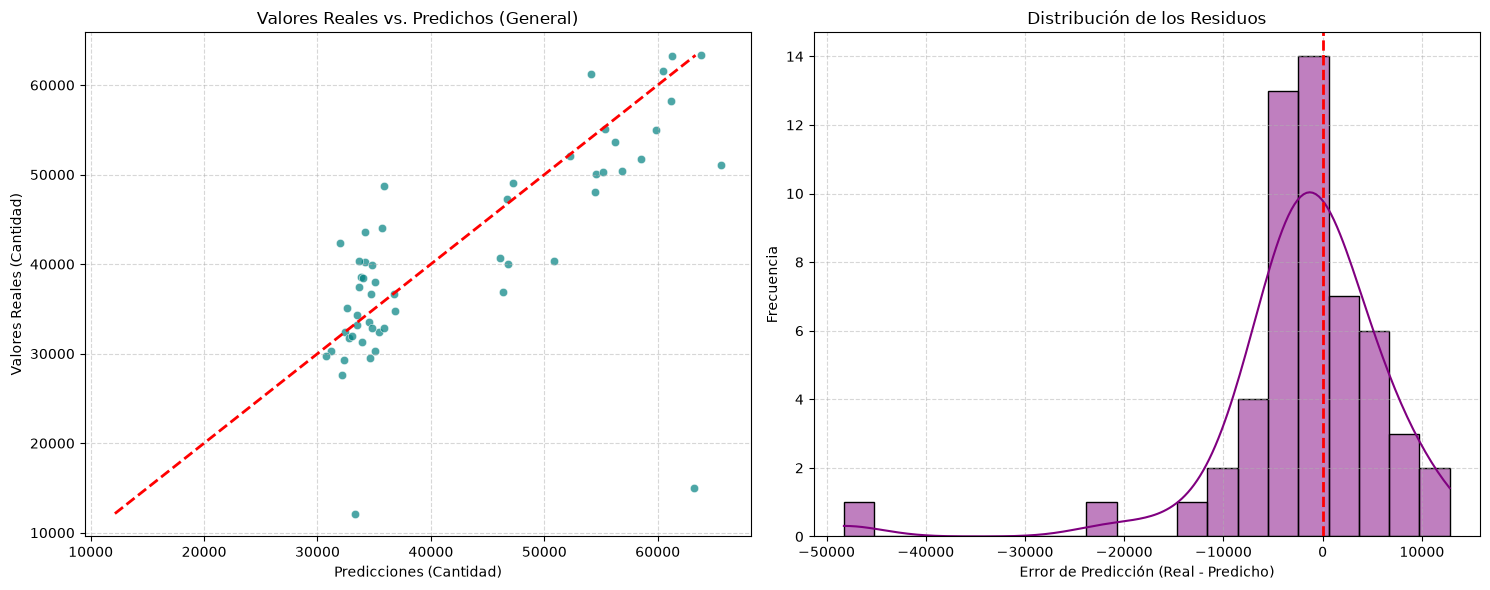

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular residuos del modelo general sobre el conjunto de prueba
# Usamos 'y_test' y las predicciones obtenidas previamente 'y_pred_best_rf'
residuos = y_test - y_pred_best_rf

# Crear la figura
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Grafico 1: Valores reales vs Predichos
sns.scatterplot(ax=axes[0], x=y_pred_best_rf, y=y_test, alpha=0.7, color='teal')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Valores Reales vs. Predichos (General)')
axes[0].set_xlabel('Predicciones (Cantidad)')
axes[0].set_ylabel('Valores Reales (Cantidad)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Grafico 2: Distribución de los residuos
sns.histplot(ax=axes[1], x=residuos, kde=True, color='purple', bins=20)
axes[1].axvline(x=0, color='red', linestyle='--', lw=2)
axes[1].set_title('Distribución de los Residuos')
axes[1].set_xlabel('Error de Predicción (Real - Predicho)')
axes[1].set_ylabel('Frecuencia')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Exportación del Modelo y Script de Inferencia

In [20]:
import joblib
import os

# Definir la ruta de guardado para el modelo
modelo_path = '../output/modelo_rf_optimizado.pkl'

# Crear la carpeta de salida si no existe
os.makedirs(os.path.dirname(modelo_path), exist_ok=True)

# Exportar el modelo optimizado
joblib.dump(best_rf, modelo_path)
print(f"Modelo guardado con éxito en: {modelo_path}")

Modelo guardado con éxito en: ../output/modelo_rf_optimizado.pkl
